# Stage 12 — Corrected Unsupervised Anomaly-Score Investigation

**Purpose:** Re-run the three unsupervised anomaly scores using the actual Stage 7 adversarial images, the frozen Stage 4 CNN, the original Stage 5 graph, and the frozen Stage 6 DGI-GCN encoder.

This notebook replaces the earlier Stage 12 run. The earlier run used random fallback feature vectors when it failed to find the Stage 7 arrays; its metrics must not be used.

## Required files in Google Drive

Create this folder:

`MyDrive/Alzheimer_DGI_Research/Stage12_Inputs/`

Place the following files directly inside it (do not rename the files):

**Three ZIP archives**
- `Stage4_CNN_Outputs.zip`
- `Stage5_Graph_Outputs.zip`
- `Stage6_DGI_Outputs.zip`

**Six Stage 7 NPZ files**
- `validation_FGSM_correct_only.npz`
- `validation_PGD_correct_only.npz`
- `validation_CW_L2_correct_only.npz`
- `test_FGSM_correct_only.npz`
- `test_PGD_correct_only.npz`
- `test_CW_L2_correct_only.npz`

The three test NPZs have already been checked. The three validation NPZs are required because the threshold must be calibrated on clean validation data using the same split-specific augmented-graph procedure. Do not substitute test data for validation data.

Run the notebook from top to bottom in Google Colab. Use a GPU runtime if available. No Stage 3 ZIP is needed for this notebook.

In [1]:
# 0. Environment and reproducibility
import os, json, zipfile, random, shutil, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.neighbors import NearestNeighbors
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", DEVICE)


PyTorch: 2.14.1+cu130 | Device: cuda


In [4]:
# 1. Mount Google Drive and locate the required inputs
from google.colab import drive
drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/Alzheimer_DGI_Research')
INPUT = ROOT / 'Stage12_Inputs'
WORK = Path('/content/stage12_corrected_work')
OUT = ROOT / 'Stage12_Corrected_Outputs'
WORK.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# Core ZIP dependencies
required_zips = ['Stage4_CNN_Outputs.zip', 'Stage5_Graph_Outputs.zip', 'Stage6_DGI_Outputs.zip']
missing_zips = [f for f in required_zips if not (INPUT / f).is_file()]
if missing_zips:
    raise FileNotFoundError(f"Missing required ZIP archives in {INPUT}:\n- " + '\n- '.join(missing_zips))

# Map of expected keys to actual files present on Google Drive
attack_prefixes = [
    'validation_FGSM', 'validation_PGD', 'validation_CW_L2',
    'test_FGSM', 'test_PGD', 'test_CW_L2'
]

# Auto-resolve names: prefer '_correct_only.npz', fall back to '_adversarial.npz'
resolved_attacks = {}
missing_attacks = []

for prefix in attack_prefixes:
    opt1 = INPUT / f"{prefix}_correct_only.npz"
    opt2 = INPUT / f"{prefix}_adversarial.npz"
    if opt1.is_file():
        resolved_attacks[prefix] = opt1
    elif opt2.is_file():
        resolved_attacks[prefix] = opt2
    else:
        missing_attacks.append(f"{prefix}_correct_only.npz (or _adversarial.npz)")

if missing_attacks:
    raise FileNotFoundError(
        'Missing required attack files in ' + str(INPUT) + ':\n- ' + '\n- '.join(missing_attacks) +
        '\nPlease upload/copy these files into Stage12_Inputs.'
    )

print('All required inputs found and resolved:')
for f in required_zips:
    print(' •', f, (INPUT/f).stat().st_size, 'bytes')
for k, path in resolved_attacks.items():
    print(' •', path.name, path.stat().st_size, 'bytes')

# Patch the notebook-wide lookup to use the resolved file paths dynamically
def load_attack_patched(split, attack):
    prefix = f"{split}_{attack}"
    path = resolved_attacks[prefix]
    with np.load(path, allow_pickle=False) as z: rec = {k:z[k] for k in z.files}
    required_keys = ['indices','original_images','adversarial_images','labels','clean_predictions',
                    'adversarial_predictions','attack_success']
    missing_keys = [k for k in required_keys if k not in rec]
    if missing_keys: raise KeyError(f'{path.name} missing keys: {missing_keys}')
    ids = rec['indices'].astype(np.int64)
    n = len(ids)
    assert n > 0 and len(np.unique(ids)) == n
    assert np.isin(ids,SPLITS[split]).all(), f'{path.name}: indices outside {split} split'
    assert rec['original_images'].shape == (n,1,128,128)
    assert rec['adversarial_images'].shape == (n,1,128,128)
    assert rec['labels'].shape == (n,) and rec['clean_predictions'].shape == (n,)
    assert rec['adversarial_predictions'].shape == (n,) and rec['attack_success'].shape == (n,)
    for key in ['original_images','adversarial_images']:
        arr = rec[key]
        assert np.isfinite(arr).all() and arr.min() >= -1e-6 and arr.max() <= 1+1e-6
    assert np.array_equal(rec['clean_predictions'],rec['labels']), f'{path.name}: input not clean-correct'
    assert np.array_equal(rec['attack_success'].astype(bool),rec['adversarial_predictions'] != rec['labels'])
    assert np.array_equal(rec['labels'],np.array([clean_label_by_idx[int(i)] for i in ids]))
    assert np.array_equal(rec['clean_predictions'],np.array([clean_pred_by_idx[int(i)] for i in ids]))
    return rec

# Injecting our resolver helper into global scope for step 5
globals()['load_attack'] = load_attack_patched

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All required inputs found and resolved:
 • Stage4_CNN_Outputs.zip 4613638 bytes
 • Stage5_Graph_Outputs.zip 2114913 bytes
 • Stage6_DGI_Outputs.zip 3242740 bytes
 • validation_FGSM_adversarial.npz 30001211 bytes
 • validation_PGD_adversarial.npz 41575369 bytes
 • validation_CW_L2_adversarial.npz 44315438 bytes
 • test_FGSM_adversarial.npz 30010576 bytes
 • test_PGD_adversarial.npz 41582650 bytes
 • test_CW_L2_adversarial.npz 44150264 bytes


In [3]:
import os
from pathlib import Path

input_dir = Path('/content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Inputs')

if input_dir.exists():
    print(f"Checking contents of: {input_dir}\n")
    files = sorted(os.listdir(input_dir))
    if not files:
        print("The directory is empty.")
    for f in files:
        file_path = input_dir / f
        size_mb = file_path.stat().st_size / (1024 * 1024) if file_path.is_file() else 0
        print(f"• {f:<40} | {'File' if file_path.is_file() else 'Folder'} | {size_mb:.2f} MB")
else:
    print(f"Directory not found: {input_dir}\nPlease ensure Google Drive is mounted and the path is correct.")

Checking contents of: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Inputs

• Stage4_CNN_Outputs.zip                   | File | 4.40 MB
• Stage5_Graph_Outputs.zip                 | File | 2.02 MB
• Stage6_DGI_Outputs.zip                   | File | 3.09 MB
• test_CW_L2_adversarial.npz               | File | 42.10 MB
• test_FGSM_adversarial.npz                | File | 28.62 MB
• test_PGD_adversarial.npz                 | File | 39.66 MB
• validation_CW_L2_adversarial.npz         | File | 42.26 MB
• validation_FGSM_adversarial.npz          | File | 28.61 MB
• validation_PGD_adversarial.npz           | File | 39.65 MB


In [5]:
# 2. Safely extract Stage 4, Stage 5 and Stage 6 archives

def safe_extract(zip_path, dest):
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        for member in zf.infolist():
            target = (dest / member.filename).resolve()
            if not str(target).startswith(str(dest.resolve()) + os.sep) and target != dest.resolve():
                raise ValueError(f'Unsafe ZIP member path: {member.filename}')
        zf.extractall(dest)

DIRS = {}
for key in ['Stage4','Stage5','Stage6']:
    dest = WORK / key.lower()
    if dest.exists(): shutil.rmtree(dest)
    safe_extract(INPUT / f'{key}_' + 'CNN_Outputs.zip' if False else INPUT / ({'Stage4':'Stage4_CNN_Outputs.zip','Stage5':'Stage5_Graph_Outputs.zip','Stage6':'Stage6_DGI_Outputs.zip'}[key]), dest)
    DIRS[key] = dest
    print(key, 'files:', [p.name for p in dest.rglob('*') if p.is_file()])

def find_exact(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename} under {root}; found {len(found)}')
    return found[0]


Stage4 files: ['cnn_test_class_metrics.csv', 'best_alzheimer_cnn.pth', 'cnn_training_history.csv', 'cnn_embeddings_128d.npz', 'cnn_embedding_manifest.csv', 'stage4_config_and_metrics.json', 'cnn_test_confusion_matrix.csv']
Stage5 files: ['cosine_knn_edges_directed.csv', 'graph_construction_config.json', 'cosine_knn_adjacency.npz', 'graph_node_manifest.csv', 'graph_node_features_and_masks.npz']
Stage6 files: ['stage6_dgi_training_history.csv', 'stage6_dgi_config.json', 'stage6_dgi_gcn_model.pt', 'stage6_dgi_graph_embeddings.npz']


## 3. Reconstruct and verify the clean CNN feature matrix

In [6]:
emb_path = find_exact(DIRS['Stage4'], 'cnn_embeddings_128d.npz')
cnn_ckpt_path = find_exact(DIRS['Stage4'], 'best_alzheimer_cnn.pth')
with np.load(emb_path, allow_pickle=False) as z:
    emb = {k: z[k] for k in z.files}

needed = ['train_embeddings','validation_embeddings','test_embeddings',
          'train_indices','validation_indices','test_indices',
          'train_labels','validation_labels','test_labels',
          'train_predictions','validation_predictions','test_predictions']
missing = [k for k in needed if k not in emb]
if missing: raise KeyError(f'Stage 4 embeddings archive missing: {missing}')
idx_train = emb['train_indices'].astype(np.int64)
idx_val = emb['validation_indices'].astype(np.int64)
idx_test = emb['test_indices'].astype(np.int64)
N = len(idx_train) + len(idx_val) + len(idx_test)
assert N == 6400, f'Expected 6400 nodes, found {N}'
assert len(np.unique(np.concatenate([idx_train,idx_val,idx_test]))) == N
X_clean = np.zeros((N,128), dtype=np.float32)
X_clean[idx_train] = emb['train_embeddings'].astype(np.float32)
X_clean[idx_val] = emb['validation_embeddings'].astype(np.float32)
X_clean[idx_test] = emb['test_embeddings'].astype(np.float32)
assert np.isfinite(X_clean).all()

# Verify Stage 4 embeddings exactly match the feature matrix used to construct Stage 5.
node_npz = find_exact(DIRS['Stage5'], 'graph_node_features_and_masks.npz')
with np.load(node_npz, allow_pickle=False) as z:
    node_data = {k:z[k] for k in z.files}
assert node_data['node_features'].shape == (N,128)
max_feature_diff = float(np.max(np.abs(X_clean - node_data['node_features'])))
print('Stage4-to-Stage5 max absolute feature difference:', max_feature_diff)
assert max_feature_diff < 1e-6, 'Stage 4 features do not match Stage 5 node features; stop.'

# Split masks must agree with Stage 5 output.
assert np.array_equal(node_data['train_mask'], np.isin(np.arange(N), idx_train))
assert np.array_equal(node_data['validation_mask'], np.isin(np.arange(N), idx_val))
assert np.array_equal(node_data['test_mask'], np.isin(np.arange(N), idx_test))
print('Clean features verified:', X_clean.shape, '| split counts:',len(idx_train),len(idx_val),len(idx_test))


Stage4-to-Stage5 max absolute feature difference: 0.0
Clean features verified: (6400, 128) | split counts: 4480 960 960


## 4. Load the exact Stage 4 CNN and verify the Stage 6 DGI-GCN checkpoint

In [7]:
class AlzheimerCNN(nn.Module):
    def __init__(self, num_classes=4, embedding_dim=128, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,32,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128,256,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.global_pool = nn.AdaptiveAvgPool2d((1,1))
        self.embedding = nn.Linear(256, embedding_dim)
        self.embedding_activation = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)
    def forward(self, x, return_embedding=False):
        x = self.features(x); x = self.global_pool(x); x = torch.flatten(x,1)
        z = self.embedding_activation(self.embedding(x))
        logits = self.classifier(self.dropout(z))
        return (logits,z) if return_embedding else logits

cnn_ckpt = torch.load(cnn_ckpt_path, map_location=DEVICE, weights_only=False)
class_names = cnn_ckpt.get('class_names', ['Mild Demented','Moderate Demented','Non-Demented','Very Mild Demented'])
cnn = AlzheimerCNN(num_classes=len(class_names)).to(DEVICE)
cnn.load_state_dict(cnn_ckpt['model_state_dict'], strict=True)
cnn.eval()
print('Stage 4 CNN checkpoint loaded; best epoch:', cnn_ckpt.get('epoch'))

# Stage 5 adjacency and its original symmetric-normalisation procedure.
A_path = find_exact(DIRS['Stage5'], 'cosine_knn_adjacency.npz')
A = sp.load_npz(A_path).tocsr().astype(np.float32)
assert A.shape == (N,N) and (A-A.T).nnz == 0
assert A.diagonal().sum() == 0 and np.isfinite(A.data).all() and np.all(A.data >= 0)
print('Stage 5 adjacency verified:', A.shape, '| undirected edges:', A.nnz//2)

# Stage 6 model architecture copied from the executed Stage 6 notebook.
class GraphConvolution(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_features,out_features))
        nn.init.xavier_uniform_(self.weight)
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None
    def forward(self, x, adj):
        support = torch.matmul(x,self.weight)
        out = torch.sparse.mm(adj,support)
        if self.bias is not None: out = out + self.bias
        return out

class GCNEncoder(nn.Module):
    def __init__(self, in_dim=128, hidden_dim=128, dropout=0.5):
        super().__init__()
        self.gc1 = GraphConvolution(in_dim,hidden_dim)
        self.gc2 = GraphConvolution(hidden_dim,hidden_dim)
        self.dropout = dropout
    def forward(self,x,adj):
        h = self.gc1(x,adj); h = F.relu(h)
        h = F.dropout(h,p=self.dropout,training=self.training)
        return self.gc2(h,adj)

def scipy_to_torch_sparse(matrix, device):
    coo = matrix.tocoo()
    indices = torch.tensor(np.vstack([coo.row,coo.col]),dtype=torch.long,device=device)
    values = torch.tensor(coo.data,dtype=torch.float32,device=device)
    return torch.sparse_coo_tensor(indices,values,coo.shape,device=device).coalesce()

def normalize_adjacency(adj):
    ahat = (adj + sp.eye(adj.shape[0],dtype=np.float32,format='csr')).tocsr()
    degree = np.asarray(ahat.sum(axis=1)).ravel().astype(np.float32)
    inv = np.power(degree,-0.5); inv[np.isinf(inv)] = 0.0
    return (sp.diags(inv) @ ahat @ sp.diags(inv)).tocsr().astype(np.float32)

A_norm = normalize_adjacency(A)
A_torch = scipy_to_torch_sparse(A_norm,DEVICE)
X_torch = torch.tensor(X_clean,dtype=torch.float32,device=DEVICE)
gcn = GCNEncoder().to(DEVICE)
dgi_ckpt_path = find_exact(DIRS['Stage6'],'stage6_dgi_gcn_model.pt')
dgi_state = torch.load(dgi_ckpt_path,map_location=DEVICE,weights_only=True)
encoder_state = {k.replace('encoder.','',1):v for k,v in dgi_state.items() if k.startswith('encoder.')}
if not encoder_state: raise KeyError('No encoder.* parameters found in Stage 6 checkpoint')
gcn.load_state_dict(encoder_state,strict=True)
gcn.eval()

stage6_npz = find_exact(DIRS['Stage6'],'stage6_dgi_graph_embeddings.npz')
with np.load(stage6_npz,allow_pickle=False) as z:
    H_stage6 = z['graph_embeddings'].astype(np.float32)
    s6_train = z['train_indices'].astype(np.int64)
    s6_val = z['val_indices'].astype(np.int64)
    s6_test = z['test_indices'].astype(np.int64)
assert np.array_equal(idx_train,s6_train) and np.array_equal(idx_val,s6_val) and np.array_equal(idx_test,s6_test)
with torch.no_grad(): H_recomputed = gcn(X_torch,A_torch).cpu().numpy().astype(np.float32)
max_dgi_diff = float(np.max(np.abs(H_recomputed-H_stage6)))
print('Stage6 embedding reconstruction max abs difference:',max_dgi_diff)
assert max_dgi_diff < 1e-4, 'Stage 6 checkpoint does not reproduce saved embeddings; stop.'


Stage 4 CNN checkpoint loaded; best epoch: 49
Stage 5 adjacency verified: (6400, 6400) | undirected edges: 43681


/tmp/ipykernel_313/1997379788.py:62: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices,values,coo.shape,device=device).coalesce()


Stage6 embedding reconstruction max abs difference: 5.960464477539062e-07


## 5. Load and rigorously validate the real Stage 7 validation/test attack files

In [10]:
ATTACKS = ['FGSM','PGD','CW_L2']
SPLITS = {'validation':idx_val,'test':idx_test}

# Map Stage 4 clean labels/predictions by original image index.
clean_label_by_idx = {}
clean_pred_by_idx = {}
for split in ['train','validation','test']:
    ids = emb[f'{split}_indices'].astype(np.int64)
    labs = emb[f'{split}_labels'].astype(np.int64)
    preds = emb[f'{split}_predictions'].astype(np.int64)
    clean_label_by_idx.update(dict(zip(ids.tolist(),labs.tolist())))
    clean_pred_by_idx.update(dict(zip(ids.tolist(),preds.tolist())))

def load_attack(split,attack):
    # Re-use our dynamic resolver dictionary from cell 895ce48e if available, otherwise fallback
    prefix = f"{split}_{attack}"
    if 'resolved_attacks' in globals() and prefix in globals()['resolved_attacks']:
        path = globals()['resolved_attacks'][prefix]
    else:
        opt1 = INPUT / f'{split}_{attack}_correct_only.npz'
        opt2 = INPUT / f'{split}_{attack}_adversarial.npz'
        path = opt1 if opt1.is_file() else opt2

    with np.load(path,allow_pickle=False) as z: rec = {k:z[k] for k in z.files}
    required = ['indices','original_images','adversarial_images','labels','clean_predictions',
                'adversarial_predictions','attack_success']
    missing = [k for k in required if k not in rec]
    if missing: raise KeyError(f'{path.name} missing keys: {missing}')

    # If the file is a full '_adversarial.npz' file instead of '_correct_only.npz',
    # filter down to only include clean-correctly predicted items
    clean_correct_mask = (rec['clean_predictions'] == rec['labels'])
    if not clean_correct_mask.all():
        print(f"[Info] Filtering {path.name}: retaining {clean_correct_mask.sum()} clean-correct samples out of {len(clean_correct_mask)} total.")
        for k in rec.keys():
            rec[k] = rec[k][clean_correct_mask]

    ids = rec['indices'].astype(np.int64)
    n = len(ids)
    assert n > 0 and len(np.unique(ids)) == n
    assert np.isin(ids,SPLITS[split]).all(), f'{path.name}: indices outside {split} split'
    assert rec['original_images'].shape == (n,1,128,128)
    assert rec['adversarial_images'].shape == (n,1,128,128)
    assert rec['labels'].shape == (n,) and rec['clean_predictions'].shape == (n,)
    assert rec['adversarial_predictions'].shape == (n,) and rec['attack_success'].shape == (n,)
    for key in ['original_images','adversarial_images']:
        arr = rec[key]
        assert np.isfinite(arr).all() and arr.min() >= -1e-6 and arr.max() <= 1+1e-6
    assert np.array_equal(rec['clean_predictions'],rec['labels']), f'{path.name}: input not clean-correct'
    assert np.array_equal(rec['attack_success'].astype(bool),rec['adversarial_predictions'] != rec['labels'])
    assert np.array_equal(rec['labels'],np.array([clean_label_by_idx[int(i)] for i in ids]))
    assert np.array_equal(rec['clean_predictions'],np.array([clean_pred_by_idx[int(i)] for i in ids]))
    return rec

attack_data = {}
for split in ['validation','test']:
    for attack in ATTACKS:
        rec = load_attack(split,attack)
        attack_data[(split,attack)] = rec
        print(split,attack,'eligible:',len(rec['indices']),'successful:',int(rec['attack_success'].sum()),
              'failed:',int((~rec['attack_success'].astype(bool)).sum()))

# Confirm test attack index sets are identical across attacks and reproduce the audited 793 samples.
test_index_sets = [set(attack_data[('test',a)]['indices'].tolist()) for a in ATTACKS]
assert test_index_sets[0] == test_index_sets[1] == test_index_sets[2]
assert len(test_index_sets[0]) == 793, f'Expected the previously audited 793 clean-correct test indices; found {len(test_index_sets[0])}'
for a in ATTACKS:
    r = attack_data[('test',a)]
    assert int(r['attack_success'].sum()) == 793 and len(r['indices']) == 793
print('Stage 7 test files verified: same 793 clean-correct test indices across all attacks.')

# The same clean-correct samples must be attacked in all three attack runs within each split.
for split in ['validation','test']:
    base = attack_data[(split,'FGSM')]
    for attack in ['PGD','CW_L2']:
        other = attack_data[(split,attack)]
        assert np.array_equal(base['indices'],other['indices']), f'{split}: index mismatch between FGSM and {attack}'
        assert np.array_equal(base['labels'],other['labels']), f'{split}: label mismatch between FGSM and {attack}'
        assert np.allclose(base['original_images'],other['original_images'],atol=1e-7), f'{split}: original image mismatch between attacks'
print('Cross-attack original-image, label and index alignment verified for validation and test.')

[Info] Filtering validation_FGSM_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation FGSM eligible: 798 successful: 797 failed: 1
[Info] Filtering validation_PGD_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation PGD eligible: 798 successful: 798 failed: 0
[Info] Filtering validation_CW_L2_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation CW_L2 eligible: 798 successful: 798 failed: 0
[Info] Filtering test_FGSM_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test FGSM eligible: 793 successful: 793 failed: 0
[Info] Filtering test_PGD_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test PGD eligible: 793 successful: 793 failed: 0
[Info] Filtering test_CW_L2_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test CW_L2 eligible: 793 successful: 793 failed: 0
Stage 7 test files verified: same 793 clean-correct test indices across all 

## 6. Extract adversarial CNN embeddings and reproduce Stage 8 symmetric graph extension

The graph extension follows the executed Stage 8 implementation: preserve clean-clean Stage 5 edges; connect each adversarial node bidirectionally to its 10 nearest clean CNN-feature nodes by cosine similarity; then recompute embeddings for clean and adversarial nodes together using the frozen Stage 6 GCN.

Validation and test augmented graphs are built separately for each attack, matching the split-specific evaluation protocol. The reference bank always contains clean training-node embeddings only.

In [11]:
K_NEIGHBORS = 10
X_unit = X_clean / np.maximum(np.linalg.norm(X_clean,axis=1,keepdims=True),1e-12)
clean_knn = NearestNeighbors(n_neighbors=K_NEIGHBORS,metric='cosine',algorithm='brute',n_jobs=-1)
clean_knn.fit(X_unit)

def extract_cnn_embeddings(images,batch_size=64):
    images = np.asarray(images,dtype=np.float32)
    outputs=[]; cnn.eval()
    with torch.no_grad():
        for start in range(0,len(images),batch_size):
            xb = torch.tensor(images[start:start+batch_size],dtype=torch.float32,device=DEVICE)
            logits,z = cnn(xb,return_embedding=True)
            outputs.append(z.cpu().numpy().astype(np.float32))
    return np.concatenate(outputs,axis=0) if outputs else np.empty((0,128),dtype=np.float32)

def build_symmetric_augmented_graph(adv_features):
    adv_features = np.asarray(adv_features,dtype=np.float32)
    if adv_features.ndim != 2 or adv_features.shape[1] != 128 or len(adv_features)==0:
        raise ValueError(f'Invalid adversarial feature shape: {adv_features.shape}')
    if not np.isfinite(adv_features).all(): raise ValueError('Non-finite adversarial features')
    adv_unit = adv_features / np.maximum(np.linalg.norm(adv_features,axis=1,keepdims=True),1e-12)
    distances, neighbor_ids = clean_knn.kneighbors(adv_unit)
    similarities = np.clip(1.0-distances,0.0,1.0).astype(np.float32)
    m=len(adv_features); rows=[]; cols=[]; vals=[]
    for j in range(m):
        new_id=N+j
        for q in range(K_NEIGHBORS):
            old_id=int(neighbor_ids[j,q]); weight=float(similarities[j,q])
            if weight>0:
                rows.extend([new_id,old_id]); cols.extend([old_id,new_id]); vals.extend([weight,weight])
    B=sp.coo_matrix((vals,(rows,cols)),shape=(N+m,N+m),dtype=np.float32).tocsr()
    A_base=sp.block_diag((A,sp.csr_matrix((m,m),dtype=np.float32)),format='csr')
    A_aug=(A_base+B).tocsr(); A_aug=A_aug.maximum(A_aug.T).tocsr()
    A_aug.setdiag(0); A_aug.eliminate_zeros()
    assert (A_aug-A_aug.T).nnz==0 and A_aug.shape==(N+m,N+m)
    return A_aug

def infer_augmented_graph(adv_images):
    adv_cnn = extract_cnn_embeddings(adv_images)
    A_aug = build_symmetric_augmented_graph(adv_cnn)
    X_aug = np.vstack([X_clean,adv_cnn]).astype(np.float32)
    A_aug_norm = normalize_adjacency(A_aug)
    A_aug_t = scipy_to_torch_sparse(A_aug_norm,DEVICE)
    X_aug_t = torch.tensor(X_aug,dtype=torch.float32,device=DEVICE)
    with torch.no_grad(): H_aug = gcn(X_aug_t,A_aug_t).cpu().numpy().astype(np.float32)
    if not np.isfinite(H_aug).all(): raise ValueError('Non-finite augmented graph embeddings')
    return H_aug, adv_cnn, int(A_aug.nnz//2)


## 7. Define the three unsupervised anomaly scores

In [12]:
# All scoring functions take a clean-training reference bank and query embeddings.
# kNN distance: mean Euclidean distance to k nearest clean training embeddings.
# Mahalanobis: Ledoit-Wolf regularised covariance estimated from clean training embeddings.
# Local affinity: 1 - mean cosine similarity to k nearest clean training embeddings.

def fit_score_models(reference,k=10):
    reference=np.asarray(reference,dtype=np.float64)
    if reference.ndim!=2 or reference.shape[1]!=128 or len(reference)<=k:
        raise ValueError(f'Invalid reference bank: {reference.shape}; must have > {k} rows and 128 columns')
    if not np.isfinite(reference).all(): raise ValueError('Reference bank has non-finite values')
    euclidean_nn=NearestNeighbors(n_neighbors=k,metric='euclidean',algorithm='brute',n_jobs=-1).fit(reference)
    cosine_nn=NearestNeighbors(n_neighbors=k,metric='cosine',algorithm='brute',n_jobs=-1).fit(reference)
    lw=LedoitWolf(assume_centered=False).fit(reference)
    return {'euclidean_nn':euclidean_nn,'cosine_nn':cosine_nn,'mahalanobis':lw,'reference':reference}

def score_embeddings(query,models):
    query=np.asarray(query,dtype=np.float64)
    euclidean_dist,_=models['euclidean_nn'].kneighbors(query)
    knn_score=euclidean_dist.mean(axis=1)
    mahal_score=np.sqrt(np.maximum(models['mahalanobis'].mahalanobis(query),0.0))
    cosine_dist,_=models['cosine_nn'].kneighbors(query)
    affinity_score=cosine_dist.mean(axis=1)  # cosine distance = 1 - cosine similarity
    return {'knn_distance':knn_score,'mahalanobis_distance':mahal_score,
            'local_affinity_anomaly':affinity_score}

METHODS=['knn_distance','mahalanobis_distance','local_affinity_anomaly']


## 8. Run validation calibration and held-out test evaluation

In [13]:
# For each attack, calibrate the three thresholds from CLEAN VALIDATION node scores only.
# Then apply those fixed thresholds to clean TEST nodes and successful adversarial TEST nodes.
# No attack labels and no test labels are used to fit score models or select thresholds.

all_metric_rows=[]; all_threshold_rows=[]; all_score_frames=[]
run_details={}
for attack in ATTACKS:
    print('\n'+'='*72+'\nAttack:',attack)
    per_split={}
    for split in ['validation','test']:
        rec=attack_data[(split,attack)]
        success=rec['attack_success'].astype(bool)
        adv_images=rec['adversarial_images'][success]
        adv_indices=rec['indices'][success].astype(np.int64)
        if len(adv_images)==0: raise RuntimeError(f'No successful {split} {attack} samples')
        t0=time.time()
        H_aug,adv_cnn,edge_count=infer_augmented_graph(adv_images)
        # The clean reference bank is exclusively the clean training nodes in this augmented graph.
        reference=H_aug[idx_train]
        models=fit_score_models(reference,k=K_NEIGHBORS)
        clean_val_scores=score_embeddings(H_aug[idx_val],models) if split=='validation' else None
        clean_test_scores=score_embeddings(H_aug[idx_test],models) if split=='test' else None
        adv_scores=score_embeddings(H_aug[N:],models)
        per_split[split]={'H_aug':H_aug,'models':models,'edge_count':edge_count,
                          'adv_indices':adv_indices,'adv_scores':adv_scores,
                          'clean_val_scores':clean_val_scores,'clean_test_scores':clean_test_scores}
        print(split,'successful adversarial nodes:',len(adv_indices),'augmented undirected edges:',edge_count,
              'elapsed minutes:',round((time.time()-t0)/60,2))

    # Thresholds are calibrated from validation clean samples, one threshold per score method.
    val_scores=per_split['validation']['clean_val_scores']
    thresholds={}
    for method in METHODS:
        tau=float(np.quantile(val_scores[method],0.95))
        thresholds[method]=tau
        all_threshold_rows.append({'attack':attack,'method':method,'calibration_split':'clean_validation',
                                   'calibration_n':len(idx_val),'target_fpr':0.05,
                                   'threshold_95th_percentile':tau,
                                   'observed_validation_fpr':float(np.mean(val_scores[method]>tau))})

    # Test negatives: all 960 clean test nodes. Test positives: only successful attacks.
    test_clean=per_split['test']['clean_test_scores']
    test_adv=per_split['test']['adv_scores']
    adv_ids=per_split['test']['adv_indices']
    for method in METHODS:
        y_true=np.concatenate([np.zeros(len(idx_test),dtype=int),np.ones(len(adv_ids),dtype=int)])
        scores=np.concatenate([test_clean[method],test_adv[method]])
        y_pred=(scores>thresholds[method]).astype(int)
        tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
        row={'attack':attack,'method':method,'threshold':thresholds[method],
             'clean_test_n':len(idx_test),'successful_adversarial_test_n':len(adv_ids),
             'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
             'precision':float(precision_score(y_true,y_pred,zero_division=0)),
             'recall':float(recall_score(y_true,y_pred,zero_division=0)),
             'f1':float(f1_score(y_true,y_pred,zero_division=0)),
             'accuracy':float(accuracy_score(y_true,y_pred)),
             'false_positive_rate':float(fp/(fp+tn)) if (fp+tn)>0 else float('nan'),
             'roc_auc':float(roc_auc_score(y_true,scores)),
             'average_precision':float(average_precision_score(y_true,scores))}
        all_metric_rows.append(row)
        print(method,'| threshold',round(thresholds[method],6),'| F1',round(row['f1'],4),
              '| AUC',round(row['roc_auc'],4),'| FPR',round(row['false_positive_rate'],4))
        # Keep per-sample test scores for audit/reproducibility.
        clean_rows=pd.DataFrame({'attack':attack,'method':method,'split':'test','sample_type':'clean',
                                 'original_index':idx_test,'detection_label':0,'anomaly_score':test_clean[method],
                                 'predicted_adversarial':(test_clean[method]>thresholds[method]).astype(int)})
        adv_rows=pd.DataFrame({'attack':attack,'method':method,'split':'test','sample_type':'successful_adversarial',
                               'original_index':adv_ids,'detection_label':1,'anomaly_score':test_adv[method],
                               'predicted_adversarial':(test_adv[method]>thresholds[method]).astype(int)})
        all_score_frames.extend([clean_rows,adv_rows])
    run_details[attack]=per_split

metrics_df=pd.DataFrame(all_metric_rows)
thresholds_df=pd.DataFrame(all_threshold_rows)
scores_df=pd.concat(all_score_frames,ignore_index=True)
display(metrics_df)
display(thresholds_df)



Attack: FGSM
validation successful adversarial nodes: 797 augmented undirected edges: 51651 elapsed minutes: 0.04
test successful adversarial nodes: 793 augmented undirected edges: 51611 elapsed minutes: 0.01
knn_distance | threshold 0.385806 | F1 0.5935 | AUC 0.8765 | FPR 0.0552
mahalanobis_distance | threshold 10.545804 | F1 0.556 | AUC 0.834 | FPR 0.0667
local_affinity_anomaly | threshold 0.006328 | F1 0.0119 | AUC 0.5579 | FPR 0.0406

Attack: PGD
validation successful adversarial nodes: 798 augmented undirected edges: 51661 elapsed minutes: 0.01
test successful adversarial nodes: 793 augmented undirected edges: 51611 elapsed minutes: 0.01
knn_distance | threshold 0.392264 | F1 0.9443 | AUC 0.9848 | FPR 0.0531
mahalanobis_distance | threshold 9.192941 | F1 0.9287 | AUC 0.9839 | FPR 0.0667
local_affinity_anomaly | threshold 0.006285 | F1 0.0 | AUC 0.6442 | FPR 0.0417

Attack: CW_L2
validation successful adversarial nodes: 798 augmented undirected edges: 51661 elapsed minutes: 0.01
t

,attack,method,threshold,clean_test_n,successful_adversarial_test_n,TN,FP,FN,TP,precision,recall,f1,accuracy,false_positive_rate,roc_auc,average_precision
0,FGSM,knn_distance,0.385806,960,793,907,53,436,357,0.870732,0.450189,0.593516,0.721050,0.055208,0.876465,0.823823
1,FGSM,mahalanobis_distance,10.545804,960,793,896,64,463,330,0.837563,0.416141,0.556024,0.699373,0.066667,0.833981,0.796288
2,FGSM,local_affinity_anomaly,0.006328,960,793,921,39,788,5,0.113636,0.006305,0.011947,0.528237,0.040625,0.557942,0.441307
3,PGD,knn_distance,0.392264,960,793,909,51,38,755,0.936725,0.952081,0.944340,0.949230,0.053125,0.984757,0.975815
4,PGD,mahalanobis_distance,9.192941,960,793,896,64,50,743,0.920694,0.936948,0.928750,0.934969,0.066667,0.983885,0.982647
5,PGD,local_affinity_anomaly,0.006285,960,793,920,40,793,0,0.000000,0.000000,0.000000,0.524815,0.041667,0.644207,0.491164
6,CW_L2,knn_distance,0.423767,960,793,908,52,715,78,0.600000,0.098361,0.169014,0.562464,0.054167,0.880866,0.731809
7,CW_L2,mahalanobis_distance,12.337900,960,793,908,52,729,64,0.551724,0.080706,0.140814,0.554478,0.054167,0.801525,0.661871
8,CW_L2,local_affinity_anomaly,0.006691,960,793,912,48,333,460,0.905512,0.580076,0.707148,0.782658,0.050000,0.920639,0.901041


,attack,method,calibration_split,calibration_n,target_fpr,threshold_95th_percentile,observed_validation_fpr
0,FGSM,knn_distance,clean_validation,960,0.05,0.385806,0.05
1,FGSM,mahalanobis_distance,clean_validation,960,0.05,10.545804,0.05
2,FGSM,local_affinity_anomaly,clean_validation,960,0.05,0.006328,0.05
3,PGD,knn_distance,clean_validation,960,0.05,0.392264,0.05
4,PGD,mahalanobis_distance,clean_validation,960,0.05,9.192941,0.05
5,PGD,local_affinity_anomaly,clean_validation,960,0.05,0.006285,0.05
6,CW_L2,knn_distance,clean_validation,960,0.05,0.423767,0.05
7,CW_L2,mahalanobis_distance,clean_validation,960,0.05,12.337900,0.05
8,CW_L2,local_affinity_anomaly,clean_validation,960,0.05,0.006691,0.05


## 9. Sanity checks, plots and export

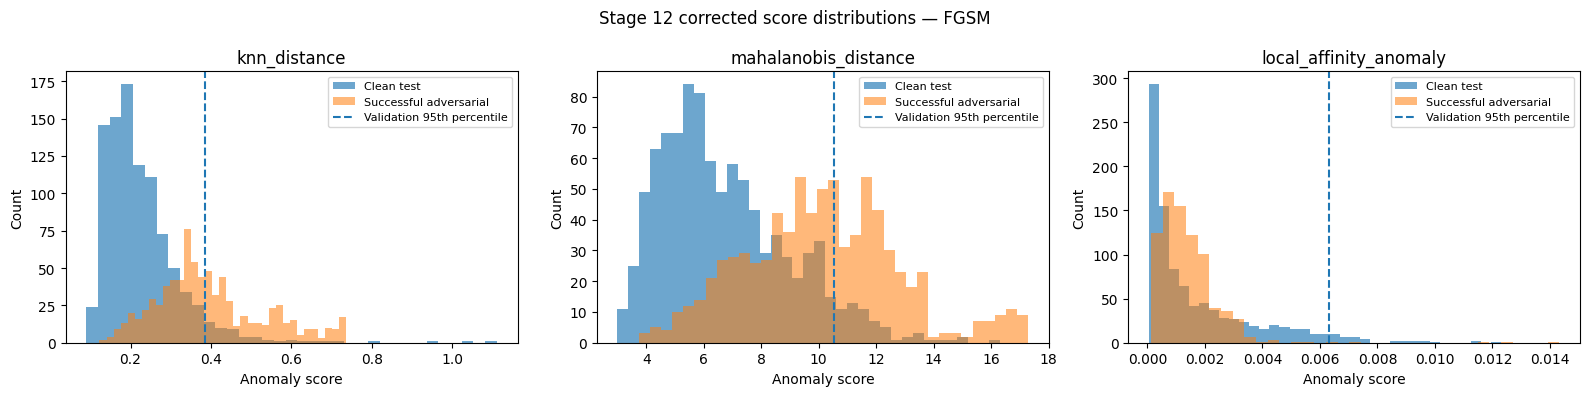

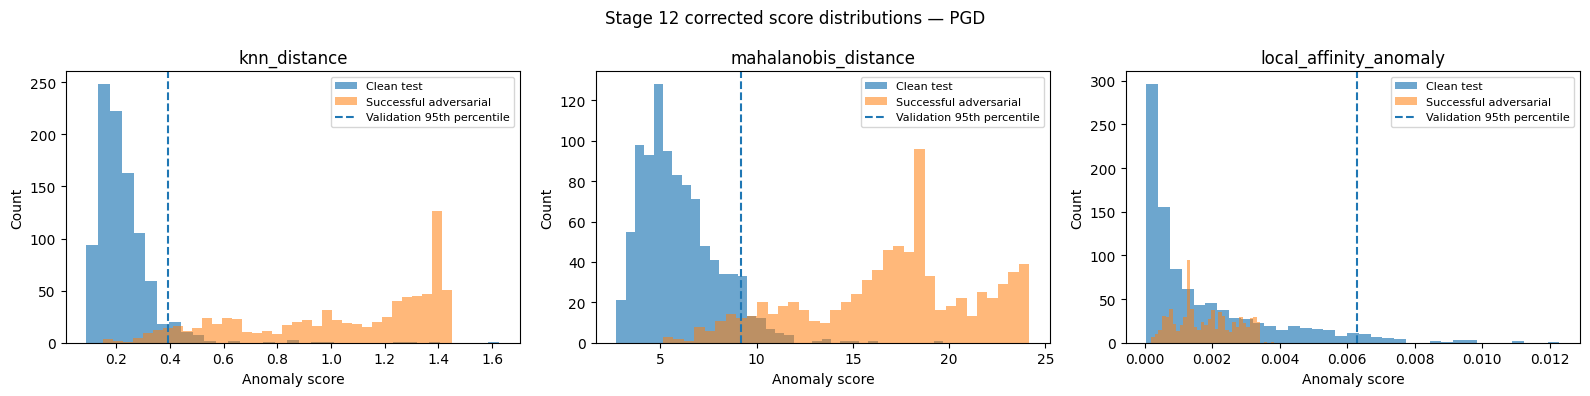

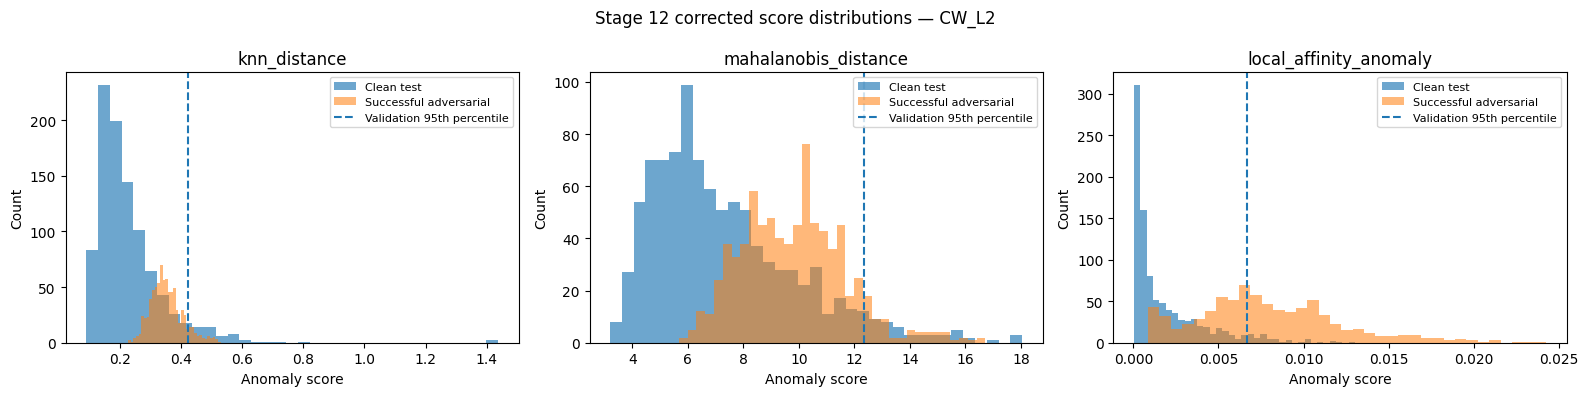

Saved outputs to: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Corrected_Outputs
Created archive: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Corrected_Outputs.zip
Final metric table:


,attack,method,threshold,clean_test_n,successful_adversarial_test_n,TN,FP,FN,TP,precision,recall,f1,accuracy,false_positive_rate,roc_auc,average_precision
0,FGSM,knn_distance,0.385806,960,793,907,53,436,357,0.870732,0.450189,0.593516,0.721050,0.055208,0.876465,0.823823
1,FGSM,mahalanobis_distance,10.545804,960,793,896,64,463,330,0.837563,0.416141,0.556024,0.699373,0.066667,0.833981,0.796288
2,FGSM,local_affinity_anomaly,0.006328,960,793,921,39,788,5,0.113636,0.006305,0.011947,0.528237,0.040625,0.557942,0.441307
3,PGD,knn_distance,0.392264,960,793,909,51,38,755,0.936725,0.952081,0.944340,0.949230,0.053125,0.984757,0.975815
4,PGD,mahalanobis_distance,9.192941,960,793,896,64,50,743,0.920694,0.936948,0.928750,0.934969,0.066667,0.983885,0.982647
5,PGD,local_affinity_anomaly,0.006285,960,793,920,40,793,0,0.000000,0.000000,0.000000,0.524815,0.041667,0.644207,0.491164
6,CW_L2,knn_distance,0.423767,960,793,908,52,715,78,0.600000,0.098361,0.169014,0.562464,0.054167,0.880866,0.731809
7,CW_L2,mahalanobis_distance,12.337900,960,793,908,52,729,64,0.551724,0.080706,0.140814,0.554478,0.054167,0.801525,0.661871
8,CW_L2,local_affinity_anomaly,0.006691,960,793,912,48,333,460,0.905512,0.580076,0.707148,0.782658,0.050000,0.920639,0.901041


In [14]:
# Sanity checks: every test positive corresponds to a successful Stage 7 attack.
for attack in ATTACKS:
    expected=int(attack_data[('test',attack)]['attack_success'].sum())
    assert expected==793, f'{attack}: expected 793 successful test attacks, found {expected}'
    assert (metrics_df.loc[metrics_df.attack==attack,'successful_adversarial_test_n']==expected).all()
assert set(metrics_df['method'])==set(METHODS)
assert np.isfinite(metrics_df[['precision','recall','f1','roc_auc','false_positive_rate']].to_numpy()).all()

# Visualise the score distributions for each attack and method.
for attack in ATTACKS:
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for ax,method in zip(axes,METHODS):
        d=scores_df[(scores_df.attack==attack)&(scores_df.method==method)]
        ax.hist(d.loc[d.sample_type=='clean','anomaly_score'],bins=35,alpha=.65,label='Clean test')
        ax.hist(d.loc[d.sample_type=='successful_adversarial','anomaly_score'],bins=35,alpha=.55,label='Successful adversarial')
        tau=float(thresholds_df[(thresholds_df.attack==attack)&(thresholds_df.method==method)]['threshold_95th_percentile'].iloc[0])
        ax.axvline(tau,linestyle='--',label='Validation 95th percentile')
        ax.set_title(method); ax.set_xlabel('Anomaly score'); ax.set_ylabel('Count'); ax.legend(fontsize=8)
    fig.suptitle(f'Stage 12 corrected score distributions — {attack}')
    fig.tight_layout()
    fig.savefig(OUT/f'stage12_{attack}_score_distributions.png',dpi=180,bbox_inches='tight')
    plt.show()

metrics_df.to_csv(OUT/'stage12_corrected_detection_metrics.csv',index=False)
thresholds_df.to_csv(OUT/'stage12_corrected_thresholds.csv',index=False)
scores_df.to_csv(OUT/'stage12_corrected_test_sample_scores.csv',index=False)

config={
 'stage':12,
 'purpose':'Corrected unsupervised anomaly-score comparison using actual Stage 7 adversarial images',
 'seed':SEED,'device':str(DEVICE),'k':K_NEIGHBORS,
 'methods':{
   'knn_distance':'mean Euclidean distance to k nearest clean training graph embeddings',
   'mahalanobis_distance':'Ledoit-Wolf regularised Mahalanobis distance fitted on clean training graph embeddings',
   'local_affinity_anomaly':'mean cosine distance (1 - cosine similarity) to k nearest clean training graph embeddings'},
 'reference_set':'clean training nodes only; embeddings recomputed in the corresponding split/attack augmented graph',
 'threshold_calibration':'95th percentile of clean validation scores, separately for each attack and score method',
 'test_evaluation':'all clean test nodes (960) versus successful adversarial test nodes only (Stage 7 success flags)',
 'stage7_test_successful_counts':{a:int(attack_data[('test',a)]['attack_success'].sum()) for a in ATTACKS},
 'attack_labels_used_for_score_fitting_or_threshold_selection':False,
 'test_labels_used_for_model_or_threshold_selection':False,
 'cnn_checkpoint':'Stage 4 best_alzheimer_cnn.pth, frozen',
 'gcn_checkpoint':'Stage 6 stage6_dgi_gcn_model.pt encoder parameters, frozen and strict-loaded',
 'graph':'Stage 5 clean-clean graph retained; adversarial nodes connected bidirectionally to k=10 cosine-nearest clean CNN-feature nodes',
 'graph_protocol':'transductive Stage 5/6 clean graph; separate symmetric augmented graph for validation and test, following Stage 8 inference procedure',
 'stage4_stage5_feature_max_abs_difference':max_feature_diff,
 'stage6_embedding_reconstruction_max_abs_difference':max_dgi_diff,
 'important_note':'Stage 6 DGI was trained transductively on all 6400 clean nodes. Results must be described as transductive; this notebook does not establish inductive generalisation.'
}
with open(OUT/'stage12_corrected_config.json','w') as f: json.dump(config,f,indent=2)

zip_path=ROOT/'Stage12_Corrected_Outputs.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob('*'):
        if p.is_file(): zf.write(p,arcname=p.name)
print('Saved outputs to:',OUT)
print('Created archive:',zip_path)
print('Final metric table:')
display(metrics_df)


## 10. Interpretation and reporting cautions

1. **Do not expect the earlier Stage 12 metrics to repeat.** Those metrics came from random fallback vectors and are invalid.
2. The detection-positive class consists only of Stage 7 successful adversarial examples. Failed attack attempts are excluded from the positive class.
3. The clean test negative class contains all 960 clean test images. Therefore, each test evaluation has 960 negatives and 793 positives for the current Stage 7 test files.
4. The 95th-percentile threshold is selected from clean validation scores only. Its empirical validation FPR may be slightly below 5% because of quantile/tie handling.
5. Stage 5/6 used a transductive graph containing all 6,400 clean nodes. State this clearly in the manuscript. A separate inductive/train-only graph experiment would be needed to support claims about unseen-node generalisation.
6. Do not copy metrics into the manuscript until the output CSVs and all assertions have been reviewed.